<a href="https://colab.research.google.com/github/TanusnSN/4NI25CS208_DAV_LAB/blob/main/4NI25CS208_EXP_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv('/content/Titanic-Dataset.csv')
df['Age'] = df['Age'].fillna(df['Age'].median())  # Fill missing Age values
features = df[['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']]
print("Original data:\n", features.head())

Original data:
    Pclass   Age  SibSp  Parch     Fare
0       3  22.0      1      0   7.2500
1       1  38.0      1      0  71.2833
2       3  26.0      0      0   7.9250
3       1  35.0      1      0  53.1000
4       3  35.0      0      0   8.0500


Min-Max Normalization (scales to 0-1)

In [6]:
minmax=MinMaxScaler()
normalized = minmax.fit_transform(features)
print('\nNormalized data (first 5 rows):\n', normalized[:5].round(3))
print("Normalized range:", normalized.min(), 'to', normalized.max())


Normalized data (first 5 rows):
 [[1.    0.271 0.125 0.    0.014]
 [0.    0.472 0.125 0.    0.139]
 [1.    0.321 0.    0.    0.015]
 [0.    0.435 0.125 0.    0.104]
 [1.    0.435 0.    0.    0.016]]
Normalized range: 0.0 to 1.0


Z-score Standardization (mean=0,std=1)

In [7]:
scalar = StandardScaler()
standardized = scalar.fit_transform(features)
print('\nStandardized data (first 5 rows):\n', standardized[:5].round(3))
print("Standardized range:", standardized.min().round(4), 'std', standardized.std().round(4))


Standardized data (first 5 rows):
 [[ 0.827 -0.566  0.433 -0.474 -0.502]
 [-1.566  0.664  0.433 -0.474  0.787]
 [ 0.827 -0.258 -0.475 -0.474 -0.489]
 [-1.566  0.433  0.433 -0.474  0.421]
 [ 0.827  0.433 -0.475 -0.474 -0.486]]
Standardized range: -2.2242 std 1.0


PCA for dimensionality reduction

In [8]:
pca = PCA(n_components=2)
principal_components = pca.fit_transform(standardized)
print("\nShape before PCA:", standardized.shape, "| Shape after PCA:", principal_components.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))
print("Total variance captured by 2 components:", round(sum(pca.explained_variance_ratio_) * 100,2), '%')


Shape before PCA: (891, 5) | Shape after PCA: (891, 2)
Explained variance ratio: [0.3396 0.3252]
Total variance captured by 2 components: 66.48 %


PCA scatter plot

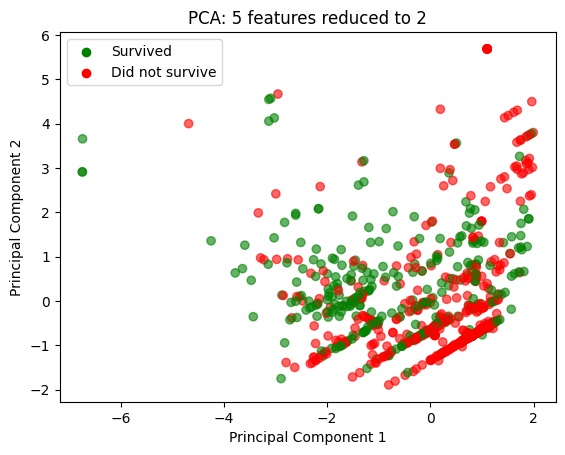

In [10]:
colors = df['Survived'].map({1: 'green', 0: 'red'})
plt.scatter(principal_components[:, 0], principal_components[:, 1], c=colors, alpha=0.6)
plt.scatter([],[],c="green", label="Survived")
plt.scatter([],[], c="red", label="Did not survive")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.title("PCA: 5 features reduced to 2")
plt.show()
